# Model 1 - Denoising Autoencoder
Run the setup cell first, then **Run all**. About 10 minutes on a T4.
Auto-resumes after a disconnect.

In [18]:
import sys, torch
ROOT = r"C:\Users\INTEL\Downloads\voice_cloning_v2_1\voice_cloning_v2_1"
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE")

GPU: NVIDIA GeForce RTX 4070


[ae] starting fresh
[ae] epoch 1/50  train=0.0534  val=0.0352  (13s)  * best
[ae] epoch 2/50  train=0.0343  val=0.0334  (12s)  * best
[ae] epoch 3/50  train=0.0329  val=0.0323  (12s)  * best
[ae] epoch 4/50  train=0.0321  val=0.0317  (12s)  * best
[ae] epoch 5/50  train=0.0317  val=0.0318  (12s)
[ae] epoch 6/50  train=0.0313  val=0.0311  (12s)  * best
[ae] epoch 7/50  train=0.0311  val=0.0310  (12s)  * best
[ae] epoch 8/50  train=0.0309  val=0.0308  (12s)  * best
[ae] epoch 9/50  train=0.0308  val=0.0306  (14s)  * best
[ae] epoch 10/50  train=0.0307  val=0.0306  (14s)  * best
[ae] epoch 11/50  train=0.0305  val=0.0307  (13s)
[ae] epoch 12/50  train=0.0305  val=0.0305  (12s)  * best
[ae] epoch 13/50  train=0.0304  val=0.0304  (12s)  * best
[ae] epoch 14/50  train=0.0303  val=0.0303  (12s)  * best
[ae] epoch 15/50  train=0.0303  val=0.0303  (12s)
[ae] epoch 16/50  train=0.0302  val=0.0303  (12s)
[ae] epoch 17/50  train=0.0301  val=0.0302  (12s)  * best
[ae] epoch 18/50  train=0.0301  val

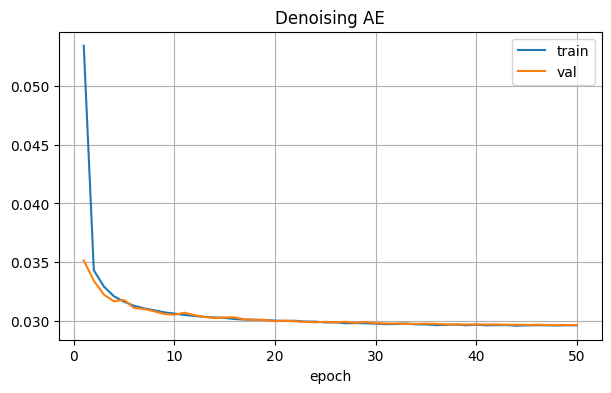

In [12]:
from vc_lib import train_ae
from vc_lib.common import plot_history

hist = train_ae.train(ROOT, epochs=50, batch_size=32, lr=1e-3)
plot_history(hist, ['train', 'val'], 'Denoising AE')

c:\Users\INTEL\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


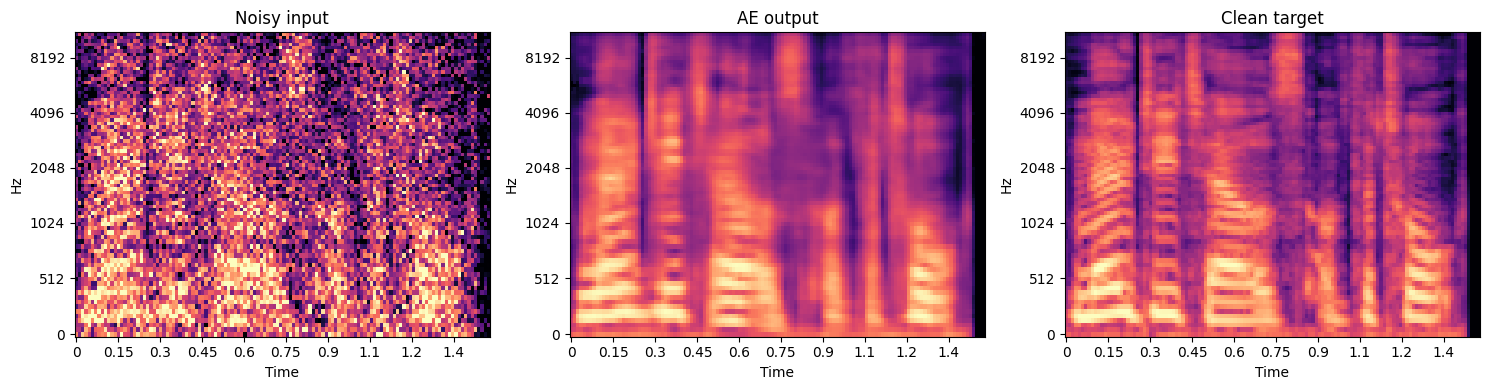

In [21]:
import torch, matplotlib.pyplot as plt, librosa.display
from vc_lib import train_ae
from vc_lib.common import paths, load_cache, mel_batch, SR
C = load_cache(paths(ROOT)); ae = train_ae.load_ae(ROOT)
clean = mel_batch(C, C['idx']['val'][:1])
noisy = train_ae.corrupt(clean, 0.2, 0.2)
with torch.no_grad(): recon = ae(noisy)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, d, t in zip(ax, [noisy, recon, clean], ['Noisy input', 'AE output', 'Clean target']):
    librosa.display.specshow(d.squeeze().cpu().numpy(), ax=a, sr=SR, hop_length=256, x_axis='time', y_axis='mel'); a.set_title(t)
plt.tight_layout(); plt.show()

In [20]:
import sys, subprocess
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "librosa", "soundfile", "num2words", "tqdm", "matplotlib"], check=True)
import librosa
print("librosa", librosa.__version__, "installed in", sys.executable)

librosa 0.11.0 installed in c:\Users\INTEL\AppData\Local\Programs\Python\Python311\python.exe
